# 1. Geodesics and logarithms

A frame is a matrix with orthonormal columns. Such a matrix can, for instance, be used to
represent a reduced basis. In order to interpolate between two frames, we need a path
along which the columns remain orthonormal; an ordinary straight line will generally
violate this constraint. We use the exponential map to construct a geodesic and then
recover its initial tangent from the endpoints. The metric is canonical throughout,
except in the comparison where the metric is varied.

## Setup

From a checkout, open the examples with
`uv run --with jupyterlab --with matplotlib jupyter lab examples/`.
Before creating the arrays we enable float64, and before importing JAX we select the CPU.
The figures use serif text with Computer Modern mathematics and
[Okabe and Ito's colors](https://jfly.uni-koeln.de/color/), supplemented by different markers and line styles.

In [1]:
import os

# Select the CPU before JAX initializes a backend.
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import platform
from pathlib import Path

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import stiefel as sf

jax.config.update("jax_enable_x64", True)
style = Path("examples/stiefel.mplstyle") if Path("examples").is_dir() else Path("stiefel.mplstyle")
plt.style.use(style)
BLUE, VERMILION, GREEN, ORANGE, INK = plt.rcParams["axes.prop_cycle"].by_key()["color"]
print(f"Python {platform.python_version()}, JAX {jax.__version__}, stiefel {sf.__version__}")
print(jax.devices())
assert jax.default_backend() == "cpu"

Python 3.13.15, JAX 0.12.0.1, stiefel 0.1.0
[CpuDevice(id=0)]


## Construct an endpoint

Let $X$ be a frame in $\mathrm{St}(40,2)$ and $D$ a tangent vector at that frame.
A geodesic from $X$ can be obtained by evaluating
$\gamma(t)=\operatorname{Exp}_X(tD)$, whose speed is constant and equal to $\|D\|_X$.
We choose the length of the tangent to be small in order to keep the endpoint near $X$.

In [2]:
frame_key, tangent_key = jax.random.split(jax.random.key(0))
x = sf.random_point(frame_key, 40, 2)
d = sf.random_tangent(tangent_key, x)
d = 0.6 * d / sf.norm(x, d)
y = sf.exp(x, d)

assert bool(sf.is_frame(y))
print("Frame shape:", y.shape)
print(f"Endpoint orthogonality error: {float(jnp.linalg.norm(y.T @ y - jnp.eye(2))):.2e}")

Frame shape: (40, 2)
Endpoint orthogonality error: 4.00e-16


## Recover the tangent

Since the endpoint was generated from a known tangent, we can compare the logarithm
with that tangent as well as check the residual of the iteration. This is a check that
would not usually be available when working with observed frames. For such frames,
the convergence flag and the endpoint residual would still have to be inspected before
the computed logarithm could be used.

In [3]:
result = sf.log(x, y)
assert bool(result.converged)
np.testing.assert_allclose(result.tangent, d, atol=1e-8)
print(f"Converged: {bool(result.converged)}, iterations: {int(result.iterations)}")
print(f"Endpoint residual: {float(result.residual):.2e}")
print(f"Tangent error: {float(jnp.linalg.norm(result.tangent - d)):.2e}")

Converged: True, iterations: 3
Endpoint residual: 4.13e-14
Tangent error: 4.39e-14


## Differentiate the path

In order to evaluate the speed along the geodesic, we use a Jacobian-vector product to obtain
its velocity, whose norm is then computed at the corresponding frame. This calculation uses
the derivative of the exponential map provided by JAX. The speed should be constant and equal
to the norm of the original tangent. We also compute the error in orthogonality, which should
be of the order of floating-point precision.

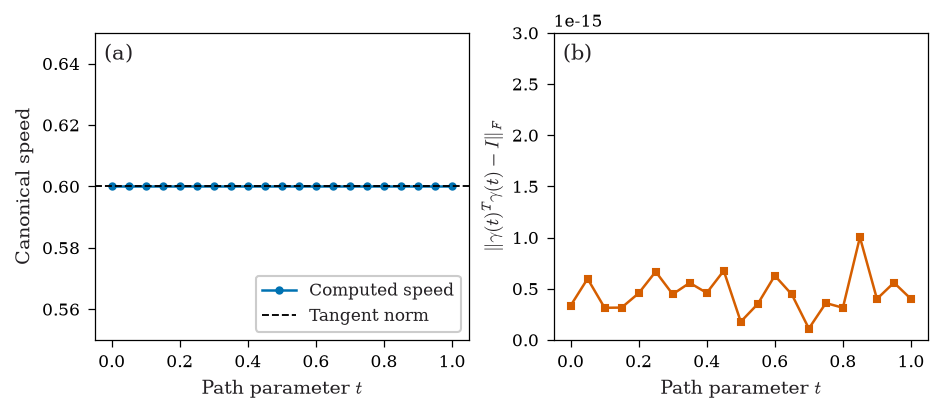

In [4]:
def path_state(t):
    point, velocity = jax.jvp(lambda s: sf.exp(x, s * d), (t,), (1.0,))
    return point, sf.norm(point, velocity)


times = jnp.linspace(0.0, 1.0, 21)
path, speeds = jax.vmap(path_state)(times)
orthogonality = jax.vmap(lambda z: jnp.linalg.norm(z.T @ z - jnp.eye(2)))(path)
np.testing.assert_allclose(speeds, sf.norm(x, d), atol=1e-9)
assert float(orthogonality.max()) < 1e-12

fig, axes = plt.subplots(1, 2, figsize=(6.17, 2.65))
axes[0].plot(times, speeds, "o-", ms=3, label="Computed speed")
axes[0].axhline(float(sf.norm(x, d)), color=INK, ls="--", lw=0.9, label="Tangent norm")
axes[0].set(xlabel=r"Path parameter $t$", ylabel="Canonical speed", ylim=(0.55, 0.65))
axes[0].legend(loc="lower right", framealpha=1)
axes[1].plot(times, orthogonality, "s-", color=VERMILION, ms=3)
axes[1].set(xlabel=r"Path parameter $t$", ylabel=r"$\|\gamma(t)^T\gamma(t)-I\|_F$", ylim=(0, 3e-15))
for ax, tag in zip(axes, ("a", "b"), strict=True):
    ax.text(0.025, 0.965, f"({tag})", transform=ax.transAxes, va="top", fontsize=10)
plt.show()

Both checks hold along this path. The exponential preserves orthogonality, while
the velocity has the prescribed canonical norm.
Differentiation through the logarithm or through statistics that call it is not supported.

## Change the metric

The package uses the metric
$$g_X(U,V)=\langle U,V\rangle_F-
\frac{1+2\alpha}{2(1+\alpha)}\langle X^TU,X^TV\rangle_F,\qquad \alpha>-1.$$
The canonical metric corresponds to $\alpha=0$, and the metric induced by the Frobenius
inner product corresponds to $\alpha=-1/2$.
For the following comparison, the endpoints are held fixed; only the metric changes.

In [5]:
for name, alpha in [("Canonical", 0.0), ("Euclidean", -0.5)]:
    metric_log = sf.log(x, y, alpha=alpha)
    assert bool(metric_log.converged)
    length = sf.norm(x, metric_log.tangent, alpha=alpha)
    print(f"{name:10s}  distance = {float(length):.6f}")

Canonical   distance = 0.600000


Euclidean   distance = 0.612928


## Check an unresolved pair

A pair with an opposite first column provides a failure case for this logarithm algorithm.
When the iteration fails, `distance` returns NaN.
More generally, convergence alone does not establish that a computed path is the shortest
one outside the local domain of the logarithm.

In [6]:
opposite = x.at[:, 0].multiply(-1.0)
failed = sf.log(x, opposite)
failed_distance = sf.distance(x, opposite)
assert not bool(failed.converged)
assert bool(jnp.isnan(failed_distance))
print("Converged:", bool(failed.converged), "distance:", float(failed_distance))

Converged: False distance: nan


## Continue with an ensemble

[Compression and means](compression-and-means.ipynb) applies these maps to an ensemble of large frames.
The [numerical notes](../docs/numerical-notes.md) give the metric conventions and the restrictions of the logarithm.